# 02 – Finalni model i rangiranje rizika
**Dodatak glavnom notebooku `analiza_revizorsko_misljenje.ipynb`** (koji ostaje netaknut).

Ovaj notebook je namjerno kratak i radi samo ono što je ostalo do kraja projekta:

1. provjera kvaliteta podataka (ID preduzeća, sektori) prije konačnih rezultata,
2. kratko poređenje 5 kandidata grupnom unakrsnom validacijom (CV) i izbor finalne konfiguracije,
3. out-of-fold procjena finalnog modela (s intervalima povjerenja) i vremenski test (trening do 2021, test od 2022),
4. definisanje kategorija rizika (nizak / srednji / visok),
5. treniranje finalnog modela na svim podacima i snimanje u datoteku (priprema za web aplikaciju),
6. rangiranje preduzeća po riziku (praktični doprinos).

Priprema podataka i modeli nalaze se u `revizija_utils.py` (isti modul će koristiti i web aplikacija).
Ciljna varijabla: `cilj_binarno` (1 = pozitivno + s rezervom, 0 = negativno + suzdržavanje). Ocjene su na nivou **izvještaja**; grupna CV drži sva preduzeća zajedno.

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')

# putanja do backenda mora biti dodana PRIJE uvoza revizija_utils
sys.path.append(os.path.abspath('../backend'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, accuracy_score, recall_score, precision_score, f1_score,
                             matthews_corrcoef, confusion_matrix, classification_report, roc_curve)

import revizija_utils as U

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 200

# ---- putanje ----
PUTANJA_PODACI = '../data/raw/dataset_revizija.csv'
PUTANJA_MODEL = '../backend/models/revizija_model.joblib'
FOLDER_REZULTATI = '../data/outputs'
os.makedirs(os.path.dirname(PUTANJA_MODEL), exist_ok=True)
os.makedirs(FOLDER_REZULTATI, exist_ok=True)

# ---- postavke ----
N_REPEATS = 10                    # broj ponavljanja grupne CV (1 = brzo testiranje)
N_SPLITS = 5
FINAL_CHOICE = 'LR | S6 omjeri'   # None = automatski najbolji po AUC
RS = U.RS

## 1. Učitavanje i provjera kvaliteta podataka

In [2]:
if not os.path.exists(PUTANJA_PODACI):
    raise FileNotFoundError(f'Dataset nije pronađen na putanji: {os.path.abspath(PUTANJA_PODACI)} '
                            f'(trenutni radni folder: {os.getcwd()})')
df = pd.read_csv(PUTANJA_PODACI)

y = df['cilj_binarno'].astype(int)
groups = df['ID_preduzeca']
print('Izvještaja:', len(df), '| različitih ID-ova preduzeća:', groups.nunique())
print('Raspon godina:', df.Godina_izvjestaja.min(), '-', df.Godina_izvjestaja.max())
print('Ciljna klasa (1 povoljno / 0 negativno):', y.value_counts().to_dict(), '| udio klase 1 =', round(y.mean(), 3))
print('Potpuni duplikati redova:', int(df.duplicated().sum()))
print('Nedostajuće vrijednosti u ulaznim kolonama:', int(df[U.RAW_COLS].isna().sum().sum()))

Izvještaja: 312 | različitih ID-ova preduzeća: 170
Raspon godina: 2004 - 2025
Ciljna klasa (1 povoljno / 0 negativno): {1: 201, 0: 111} | udio klase 1 = 0.644
Potpuni duplikati redova: 0
Nedostajuće vrijednosti u ulaznim kolonama: 2


In [3]:
# ID koji se u istoj godini javlja više puta: sumnjivo, jer jedno preduzeće ima jedan godišnji izvještaj.
# Ako su finansije različite, vjerovatno je riječ o različitim preduzećima s istim (automatski dodijeljenim) ID-em.
dup = df.groupby(['ID_preduzeca', 'Godina_izvjestaja']).size().rename('broj_izvjestaja').reset_index()
dup = dup[dup.broj_izvjestaja > 1]
print('Kombinacija ID + godina s više od jednog izvještaja:', len(dup), '| ID-ova na koje se to odnosi:', dup.ID_preduzeca.nunique())
print('Redova u tim kombinacijama:', int(dup.broj_izvjestaja.sum()), 'od', len(df))
display_cols = ['ID_preduzeca', 'Sektor', 'Godina_izvjestaja', 'poslovna_imovina_t', 'prihod_prodaja_t', 'misljenje']
sumnjivi = df.merge(dup[['ID_preduzeca', 'Godina_izvjestaja']], on=['ID_preduzeca', 'Godina_izvjestaja'])[display_cols]
sumnjivi.sort_values(['ID_preduzeca', 'Godina_izvjestaja']).head(15)

Kombinacija ID + godina s više od jednog izvještaja: 4 | ID-ova na koje se to odnosi: 3
Redova u tim kombinacijama: 9 od 312


,ID_preduzeca,Sektor,Godina_izvjestaja,poslovna_imovina_t,prihod_prodaja_t,misljenje
0,P002,Energetika i rudarstvo,2018,585608835,98336465,Negativno mišljenje
1,P002,Energetika i rudarstvo,2018,180405648,67346322,Negativno mišljenje
2,P002,Energetika i rudarstvo,2018,64556721,12202060,Negativno mišljenje
5,P042,Saobraćaj i infrastruktura,2011,13921021,11378609,Mišljenje s rezervom
6,P042,Saobraćaj i infrastruktura,2011,2284925350,60719191,Mišljenje s rezervom
3,P042,Saobraćaj i infrastruktura,2013,2387243423,57104062,Mišljenje s rezervom
4,P042,Saobraćaj i infrastruktura,2013,12883725,11270646,Negativno mišljenje
7,P045,Telekomunikacije i pošta,2019,30072737,25629427,Mišljenje s rezervom
8,P045,Zdravstvo i socijalna zaštita,2019,17887424,12866780,Mišljenje s rezervom


In [4]:
print('Sektor "Ostalo (provjeriti)":', int((df.Sektor.str.contains('provjeriti', na=False)).sum()), 'izvještaj(a)')
print()
print('Izvještaja po godini:'); print(df.Godina_izvjestaja.value_counts().sort_index().to_dict())
print()
print('Broj izvještaja po ID-u (distribucija):'); print(groups.value_counts().value_counts().sort_index().to_dict())

Sektor "Ostalo (provjeriti)": 1 izvještaj(a)

Izvještaja po godini:
{2004: 3, 2005: 8, 2006: 5, 2007: 7, 2008: 9, 2009: 9, 2010: 12, 2011: 14, 2012: 12, 2013: 12, 2014: 10, 2015: 8, 2016: 15, 2017: 19, 2018: 24, 2019: 33, 2020: 19, 2021: 21, 2022: 18, 2023: 25, 2024: 17, 2025: 12}

Broj izvještaja po ID-u (distribucija):
{1: 126, 2: 18, 3: 8, 4: 6, 6: 3, 7: 2, 8: 1, 9: 2, 10: 2, 11: 1, 13: 1}


**Napomena za tumačenje:** ako ID-ovi nisu pouzdani, grupna CV ne drži tačno sva preduzeća zajedno, pa je procjena donekle optimistična. Ako se ID-ovi isprave u CSV-u, cijeli notebook se jednostavno ponovo pokrene.

## 2. Kandidati: grupna CV i izbor finalne konfiguracije
Svi kandidati se ocjenjuju na istim podjelama (`StratifiedGroupKFold`, ponovljeno `N_REPEATS` puta), uz `DummyClassifier` kao osnovni nivo.

In [5]:
from sklearn.metrics import make_scorer
scoring = {'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy',
           'f1': 'f1', 'mcc': make_scorer(matthews_corrcoef),
           'recall_neg': make_scorer(recall_score, pos_label=0),
           'precision_neg': make_scorer(precision_score, pos_label=0, zero_division=0)}

def grupni_cv(model, X, repeats=N_REPEATS):
    out = {k: [] for k in scoring}
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=r)
        s = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring, n_jobs=-1)
        for k in out: out[k].extend(s['test_' + k])
    return {k: np.array(v) for k, v in out.items()}

REZ = {}
for naziv, (skup, fabrika) in U.KANDIDATI.items():
    REZ[naziv] = grupni_cv(fabrika(), U.napravi_X(df, skup))
    print('gotovo:', naziv)
REZ['Osnovni nivo (većinska klasa)'] = grupni_cv(DummyClassifier(strategy='prior'), U.napravi_X(df, 'S1'))

tab = pd.DataFrame({n: {k: v.mean() for k, v in d.items()} for n, d in REZ.items()}).T
tab['std_AUC'] = [d['roc_auc'].std() for d in REZ.values()]
tab.sort_values('roc_auc', ascending=False)

gotovo: LR | S6 omjeri
gotovo: LR | S1 sirove
gotovo: SVM | S7 sirove+omjeri
gotovo: MLP | S1 sirove
gotovo: RF | S6 omjeri


,roc_auc,accuracy,balanced_accuracy,f1,mcc,recall_neg,precision_neg,std_AUC
SVM | S7 sirove+omjeri,0.752,0.707,0.703,0.754,0.392,0.690,0.574,0.075
MLP | S1 sirove,0.745,0.697,0.672,0.762,0.342,0.578,0.577,0.083
RF | S6 omjeri,0.736,0.689,0.641,0.767,0.299,0.471,0.585,0.070
LR | S1 sirove,0.731,0.654,0.655,0.701,0.299,0.659,0.516,0.081
LR | S6 omjeri,0.729,0.685,0.673,0.740,0.339,0.631,0.554,0.079
Osnovni nivo (većinska klasa),0.500,0.644,0.500,0.781,0.000,0.000,0.000,0.000


In [6]:
kand_tab = tab.drop(index='Osnovni nivo (većinska klasa)')
best_auto = kand_tab['roc_auc'].idxmax()
FINAL = FINAL_CHOICE or best_auto
SKUP, FABRIKA = U.KANDIDATI[FINAL]
X = U.napravi_X(df, SKUP)
print('Automatski najbolji po AUC:', best_auto)
print('FINALNA konfiguracija   :', FINAL, '| skup atributa:', SKUP, '| broj atributa:', X.shape[1])
print()
razlika = kand_tab['roc_auc'].max() - kand_tab['roc_auc'].min()
print(f'Razlika AUC između najboljeg i najslabijeg kandidata: {razlika:.3f}. '
      'Ako je mala, izbor modela je praktično stvar jednostavnosti i objašnjivosti, a ne tačnosti.')

Automatski najbolji po AUC: SVM | S7 sirove+omjeri
FINALNA konfiguracija   : LR | S6 omjeri | skup atributa: S6 | broj atributa: 19

Razlika AUC između najboljeg i najslabijeg kandidata: 0.023. Ako je mala, izbor modela je praktično stvar jednostavnosti i objašnjivosti, a ne tačnosti.


## 3. Out-of-fold procjena finalnog modela
Svaki izvještaj ocjenjuje model koji ga nije vidio (a ni njegovo preduzeće, preko grupa). Intervali povjerenja: cluster bootstrap po preduzećima.

In [18]:
cv_oof = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=1)
oof = cross_val_predict(FABRIKA(), X, y, cv=cv_oof, groups=groups, method='predict_proba')[:, 1]
pred = (oof >= 0.5).astype(int)

print(classification_report(y, pred, target_names=['Negativno (0) – RIZIK', 'Povoljno (1)'], digits=3))
print('ROC AUC =', round(roc_auc_score(y, oof), 3), '| MCC =', round(matthews_corrcoef(y, pred), 3),
      '| accuracy =', round(accuracy_score(y, pred), 3), '| osnovni nivo =', round(max(y.mean(), 1 - y.mean()), 3))

rng = np.random.default_rng(RS)
ids = groups.values; jed = np.unique(ids); idx_po_id = {g: np.where(ids == g)[0] for g in jed}
m = {'ROC AUC': [], 'Accuracy': [], 'Recall (negativno)': [], 'Precision (negativno)': []}
for _ in range(1000):
    idx = np.concatenate([idx_po_id[g] for g in rng.choice(jed, size=len(jed), replace=True)])
    if y.values[idx].min() == y.values[idx].max(): continue
    pb = (oof[idx] >= 0.5).astype(int)
    m['ROC AUC'].append(roc_auc_score(y.values[idx], oof[idx]))
    m['Accuracy'].append(accuracy_score(y.values[idx], pb))
    m['Recall (negativno)'].append(recall_score(y.values[idx], pb, pos_label=0, zero_division=0))
    m['Precision (negativno)'].append(precision_score(y.values[idx], pb, pos_label=0, zero_division=0))
ci = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in m.items()},
                  index=['Prosjek', '2.5%', '97.5%']).T
print('\n95% interval povjerenja (cluster bootstrap po preduzećima):'); ci

                       precision    recall  f1-score   support

Negativno (0) – RIZIK      0.592     0.640     0.615       111
         Povoljno (1)      0.792     0.756     0.774       201

             accuracy                          0.715       312
            macro avg      0.692     0.698     0.694       312
         weighted avg      0.721     0.715     0.717       312

ROC AUC = 0.744 | MCC = 0.39 | accuracy = 0.715 | osnovni nivo = 0.644

95% interval povjerenja (cluster bootstrap po preduzećima):


,Prosjek,2.5%,97.5%
ROC AUC,0.742,0.673,0.807
Accuracy,0.714,0.654,0.768
Recall (negativno),0.635,0.531,0.733
Precision (negativno),0.589,0.488,0.687


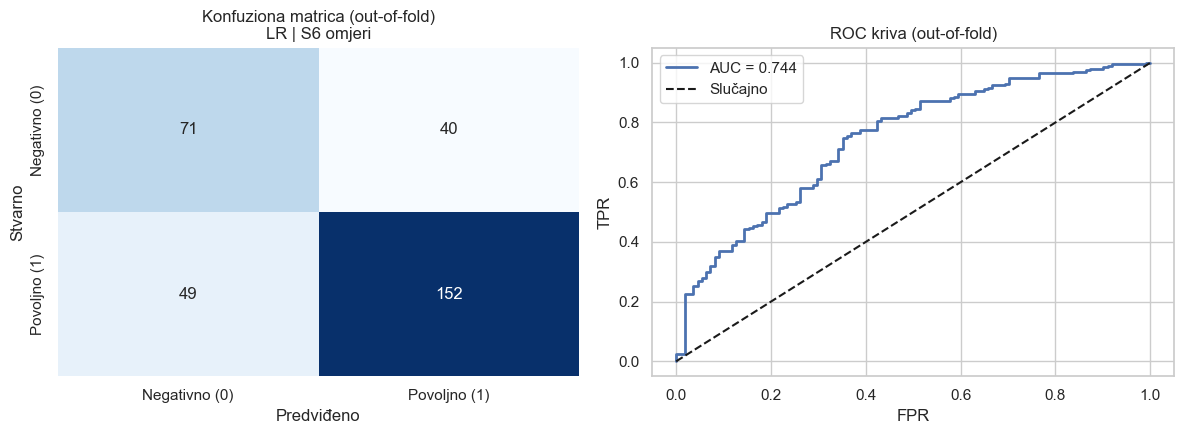

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['Negativno (0)', 'Povoljno (1)'], yticklabels=['Negativno (0)', 'Povoljno (1)'])
ax[0].set_title(f'Konfuziona matrica (out-of-fold)\n{FINAL}'); ax[0].set_xlabel('Predviđeno'); ax[0].set_ylabel('Stvarno')
fpr, tpr, _ = roc_curve(y, oof)
ax[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y, oof):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--', label='Slučajno')
ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].set_title('ROC kriva (out-of-fold)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Vremenski test (trening do 2021, test od 2022)
Preporuka mentorice. Test skup je mali, pa rezultat treba tumačiti oprezno; ovdje je prikazan samo za finalnu konfiguraciju (bez ponovnog biranja modela prema test skupu).

In [9]:
tr = (df.Godina_izvjestaja <= 2021).values; te = (df.Godina_izvjestaja >= 2022).values
mdl = FABRIKA().fit(X[tr], y[tr])
p_te = mdl.predict_proba(X[te])[:, 1]; pr_te = (p_te >= 0.5).astype(int); yt = y[te]
print(f'Trening: {tr.sum()} izvještaja | test: {te.sum()} izvještaja | udio klase 1 u testu: {yt.mean():.3f}')
print(f'ROC AUC = {roc_auc_score(yt, p_te):.3f} | accuracy = {accuracy_score(yt, pr_te):.3f} (osnovni nivo {max(yt.mean(), 1-yt.mean()):.3f})'
      f' | MCC = {matthews_corrcoef(yt, pr_te):.3f}')
print(f'Recall (negativno) = {recall_score(yt, pr_te, pos_label=0):.3f} | Precision (negativno) = {precision_score(yt, pr_te, pos_label=0, zero_division=0):.3f}')
print(pd.DataFrame(confusion_matrix(yt, pr_te), index=['stvarno 0', 'stvarno 1'], columns=['predviđeno 0', 'predviđeno 1']))

Trening: 240 izvještaja | test: 72 izvještaja | udio klase 1 u testu: 0.667
ROC AUC = 0.732 | accuracy = 0.722 (osnovni nivo 0.667) | MCC = 0.351
Recall (negativno) = 0.500 | Precision (negativno) = 0.600
           predviđeno 0  predviđeno 1
stvarno 0            12            12
stvarno 1             8            40


## 5. Kategorije rizika
Model daje interni **skor rizika**. Napomena: to nije kalibrirana vjerovatnoća (model je zbog `class_weight='balanced'` sistematski previsok), pa se korisniku ne prikazuje kao procenat. Za praktičnu upotrebu koristimo **rang**: gornjih 30% izvještaja po riziku = **povišen rizik**, ostalo = **uobičajen rizik**. Prag je određen na out-of-fold rizicima. (Srednja kategorija je izostavljena jer se njen udio negativnih mišljenja ne razlikuje od prosjeka.)

In [10]:
rizik = 1 - oof
PRAG_POVISEN = float(np.quantile(rizik, 0.70))   # gornjih 30% = povišen rizik
kat = np.where(rizik >= PRAG_POVISEN, 'povišen', 'uobičajen')
neg = 1 - y.values
osn = neg.mean()
rows = []
for k in ['povišen', 'uobičajen']:
    mk = kat == k
    rows.append({'Kategorija': k, 'Broj izvještaja': int(mk.sum()), 'Udio negativnih mišljenja': neg[mk].mean(),
                 'Lift naspram prosjeka': neg[mk].mean() / osn})
print(f'Prag povišenog rizika: skor >= {PRAG_POVISEN:.3f} | osnovni udio negativnih: {osn:.3f}')
kat_tab = pd.DataFrame(rows); kat_tab

Prag povišenog rizika: skor >= 0.579 | osnovni udio negativnih: 0.356


,Kategorija,Broj izvještaja,Udio negativnih mišljenja,Lift naspram prosjeka
0,povišen,94,0.617,1.734
1,uobičajen,218,0.243,0.683


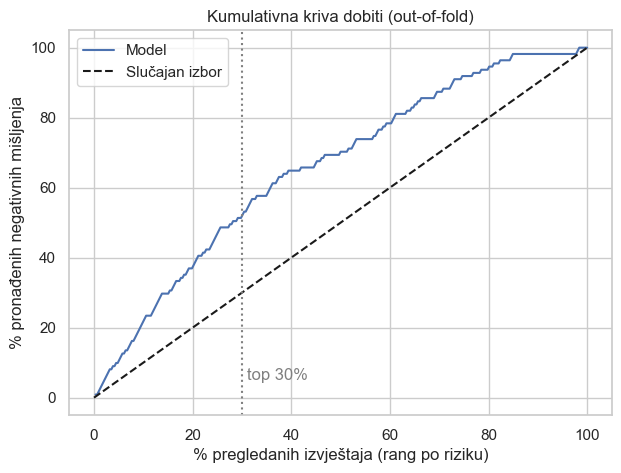

Top 30% po riziku obuhvata 51% svih negativnih mišljenja.


In [11]:
# kumulativna kriva dobiti: koliko negativnih mišljenja uhvatimo ako pregledamo top x% po riziku
red = np.argsort(-rizik); kum = np.cumsum(neg[red]) / neg.sum()
plt.figure(figsize=(7, 5))
plt.plot(np.arange(1, len(red) + 1) / len(red) * 100, kum * 100, label='Model')
plt.plot([0, 100], [0, 100], 'k--', label='Slučajan izbor')
plt.axvline(30, color='gray', ls=':'); plt.text(31, 5, 'top 30%', color='gray')
plt.xlabel('% pregledanih izvještaja (rang po riziku)'); plt.ylabel('% pronađenih negativnih mišljenja')
plt.title('Kumulativna kriva dobiti (out-of-fold)'); plt.legend(); plt.show()
print(f'Top 30% po riziku obuhvata {kum[int(0.3*len(red))-1]*100:.0f}% svih negativnih mišljenja.')

## 6. Finalni model: treniranje na svim podacima i snimanje
Model treniran na svim izvještajima snima se zajedno s pragom rizika, raspodjelom out-of-fold skorova (za izračun percentila), rasponima unosa i referentnim medijanima omjera. Datoteka `revizija_model.joblib` je ono što koristi web aplikacija. **Napomena:** metrike u ovom notebooku računate su out-of-fold, ne na ovom modelu (on je vidio sve podatke).

In [12]:
final_model = FABRIKA().fit(X, y)
ref = U.napravi_referentne(df, rizik, PRAG_POVISEN)
paket = {'model': final_model, 'skup': SKUP, 'naziv': FINAL,
         'prag_povisen': PRAG_POVISEN, 'oof_rizik_sortirano': np.sort(rizik), 'referentne': ref,
         'n_izvjestaja': len(df), 'godine': (int(df.Godina_izvjestaja.min()), int(df.Godina_izvjestaja.max())),
         'cv_auc': float(roc_auc_score(y, oof))}
joblib.dump(paket, PUTANJA_MODEL)

# provjera: ponovno učitavanje i skoriranje (ovo je tačno ono što radi aplikacija)
p2 = joblib.load(PUTANJA_MODEL)
print(U.skoruj(df[U.RAW_COLS].head(5), p2))
print('Snimljeno:', os.path.abspath(PUTANJA_MODEL), '| konfiguracija:', FINAL)

   rizik_skor  percentil kategorija_rizika upozorenja
0       0.919     96.000           povišen         []
1       0.766     84.000           povišen         []
2       0.759     84.000           povišen         []
3       0.841     91.000           povišen         []
4       0.461     54.000         uobičajen         []
Snimljeno: c:\Users\userr\Desktop\Data-mining-u-funkciji-detekcije-netacnih-finansijskih-izvjestaja-javnih-preduzeca\backend\models\revizija_model.joblib | konfiguracija: LR | S6 omjeri


### Primjer odgovora za aplikaciju
Ovo je tačan oblik podataka koje će backend vraćati frontendu. Drugi dio pokazuje kako provjera unosa hvata pogrešne jedinice i negativne vrijednosti.

In [13]:
import json
primjer = df[U.RAW_COLS].iloc[[0]]
odgovor = {'rezultat': U.skoruj(primjer, p2).iloc[0].to_dict(),
           'usporedba_omjera': U.usporedba_omjera(primjer, p2)[0]}
print(json.dumps(odgovor, ensure_ascii=False, indent=2, default=float))

print('\n--- provjera unosa ---')
pogresne_jedinice = primjer.copy(); pogresne_jedinice[U.RAW_COLS] = pogresne_jedinice[U.RAW_COLS] / 1000
print('Pogrešne jedinice (/1000):', U.skoruj(pogresne_jedinice, p2).upozorenja.iloc[0])
neg_unos = primjer.copy(); neg_unos['poslovna_imovina_t'] = -5
print('Negativna imovina        :', U.skoruj(neg_unos, p2).upozorenja.iloc[0])

{
  "rezultat": {
    "rizik_skor": 0.9188,
    "percentil": 96.0,
    "kategorija_rizika": "povišen",
    "upozorenja": []
  },
  "usporedba_omjera": [
    {
      "omjer": "zaduzenost_t",
      "naziv": "Zaduženost (obaveze / imovina)",
      "vrijednost": 0.6907,
      "medijan_uzorak": 0.2352,
      "medijan_povisen": 0.543
    },
    {
      "omjer": "kratk_obaveze_udio_t",
      "naziv": "Udio kratkoročnih obaveza u imovini",
      "vrijednost": 0.6907,
      "medijan_uzorak": 0.1225,
      "medijan_povisen": 0.3981
    },
    {
      "omjer": "likvidnost_t",
      "naziv": "Likvidnost (obrtna imovina / kratkoročne obaveze)",
      "vrijednost": 0.0612,
      "medijan_uzorak": 1.6706,
      "medijan_povisen": 0.5949
    },
    {
      "omjer": "marza_t",
      "naziv": "Poslovna marža",
      "vrijednost": -0.2541,
      "medijan_uzorak": -0.0243,
      "medijan_povisen": -0.0858
    },
    {
      "omjer": "potraz_prihod_t",
      "naziv": "Potraživanja / prihodi",
      "vrijed

In [14]:
# predložak CSV-a za unos (jedan red = jedan izvještaj), može se koristiti u aplikaciji
predlozak = pd.DataFrame(columns=['ID_preduzeca'] + U.RAW_COLS)
predlozak.to_csv(f'{FOLDER_REZULTATI}/predlozak_unos.csv', index=False)
print('Kolone predloška:', len(predlozak.columns), '| snimljeno u', os.path.abspath(FOLDER_REZULTATI))

Kolone predloška: 24 | snimljeno u c:\Users\userr\Desktop\Data-mining-u-funkciji-detekcije-netacnih-finansijskih-izvjestaja-javnih-preduzeca\data\outputs


## 7. Rangiranje preduzeća po riziku (praktični doprinos)
Za svako preduzeće uzima se **najnoviji izvještaj** i njegov out-of-fold rizik (procjena koju nije vidio model). Ovo je retrospektivna provjera: u koloni *stvarno mišljenje* vidi se koliko su visoko rangirana preduzeća zaista imala nepovoljno mišljenje.

In [15]:
r = df[['ID_preduzeca', 'Sektor', 'Godina_izvjestaja', 'misljenje']].copy()
r['rizik'] = rizik; r['kategorija'] = kat; r['negativno'] = neg
najnoviji = r.sort_values('Godina_izvjestaja').drop_duplicates('ID_preduzeca', keep='last')
rang = najnoviji.sort_values('rizik', ascending=False).reset_index(drop=True)
rang.index += 1
top = rang.head(15)
print(f'Preduzeća (najnoviji izvještaj): {len(rang)} | među top 15: negativno mišljenje {top.negativno.mean():.0%} (u svim: {rang.negativno.mean():.0%})')
rang.head(15)[['ID_preduzeca', 'Sektor', 'Godina_izvjestaja', 'rizik', 'kategorija', 'misljenje']]

Preduzeća (najnoviji izvještaj): 170 | među top 15: negativno mišljenje 80% (u svim: 34%)


,ID_preduzeca,Sektor,Godina_izvjestaja,rizik,kategorija,misljenje
1,P136,Industrija i proizvodnja,2022,1.000,povišen,Negativno mišljenje
2,P083,Zdravstvo i socijalna zaštita,2019,0.994,povišen,Mišljenje s rezervom
3,P013,"Mediji, sport, turizam i kultura",2024,0.966,povišen,Negativno mišljenje
4,P153,Energetika i rudarstvo,2023,0.961,povišen,Negativno mišljenje
5,P073,Industrija i proizvodnja,2019,0.961,povišen,Negativno mišljenje
6,P070,Komunalne djelatnosti,2005,0.929,povišen,Negativno mišljenje
7,P061,Saobraćaj i infrastruktura,2022,0.924,povišen,Negativno mišljenje
8,P122,Šumarstvo i poljoprivreda,2021,0.921,povišen,Mišljenje s rezervom
9,P059,Komunalne djelatnosti,2019,0.910,povišen,Negativno mišljenje
10,P001,Saobraćaj i infrastruktura,2018,0.908,povišen,Negativno mišljenje


In [16]:
rang.to_csv(f'{FOLDER_REZULTATI}/rang_preduzeca_po_riziku.csv', index_label='rang')
print('Snimljeno:', os.path.abspath(f'{FOLDER_REZULTATI}/rang_preduzeca_po_riziku.csv'))

Snimljeno: c:\Users\userr\Desktop\Data-mining-u-funkciji-detekcije-netacnih-finansijskih-izvjestaja-javnih-preduzeca\data\outputs\rang_preduzeca_po_riziku.csv


## Zaključak i sljedeći koraci
- Finalna konfiguracija, out-of-fold metrike s intervalima povjerenja, vremenski test i kategorije rizika nalaze se gore; brojeve iz ovog notebooka treba koristiti u radu (ne mijenjati ih ručno).
- Model je alat za **rangiranje rizika**, ne dokaz prevare ni predviđanje vrste mišljenja. Korisniku se prikazuju kategorija i percentil, ne procenat vjerovatnoće.
- Sljedeći korak: web aplikacija (`revizija_model.joblib` + `revizija_utils.py` + `predlozak_unos.csv`).